# Proyecto Integrador de Ciencia de Datos
## Fase 3, actividad 6: Evaluación comparativa, optimización e interpretabilidad (Entregable 3)

**Universidad de La Salle**, Maestría en Inteligencia Artificial
**Asignatura:** Ciencia de Datos (2026-2). **Docente:** Fabián Camilo Castro Riveros
**Estudiante:** Martín Gracia Socha (trabajo individual)
**Conjunto de datos:** METABRIC

### Contenido
1. Configuración y reglas de decisión
2. Optimización: reducir la brecha de sobreajuste en clasificación
3. Selección de los modelos finales (solo con validación cruzada)
4. Evaluación final en el conjunto de prueba: regresión
5. Evaluación final en el conjunto de prueba: clasificación
6. Interpretabilidad: SHAP, coeficientes e importancia por permutación
7. Clustering: validación en prueba y genes que definen los grupos
8. Cumplimiento de los objetivos SMART y conclusiones

> El Entregable 3 lo forman los cuadernos 04 (modelado y ajuste de hiperparámetros), 05 (MLP en PyTorch) y este.

> **Ejecución en Google Colab.** Los modelos de `models/` se guardaron con scikit-learn 1.9.1. Si Colab tiene otra versión, ejecute primero el cuaderno 04 en la misma sesión para regenerarlos; así este cuaderno cargará modelos compatibles. En un entorno local con `requirements.txt` no hace falta.

## 1. Configuración y reglas de decisión

In [1]:
import sys
import json
import time
import warnings
from pathlib import Path

# --- Entorno: en Google Colab se clona el repositorio y se instalan dependencias faltantes ---
IN_COLAB = "google.colab" in sys.modules
REPO_URL = "https://github.com/MartinGia/metabric-proyecto-integrador.git"
if IN_COLAB:
    # En Colab se clona el repositorio (datos, código y modelos) y se instalan las librerías que Colab no trae.
    import os, subprocess, importlib.util
    repo_dir = Path("/content/metabric-proyecto-integrador")
    if not (repo_dir / "src" / "config.py").exists():
        subprocess.run(["git", "clone", "--depth", "1", REPO_URL, str(repo_dir)], check=True)
    os.chdir(repo_dir / "notebooks")
    for pkg, module in [("imbalanced-learn", "imblearn"), ("xgboost", "xgboost"), ("shap", "shap")]:
        if importlib.util.find_spec(module) is None:
            subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=True)

def find_project_root():
    for c in [Path.cwd(), *Path.cwd().parents]:
        if (c / "src" / "config.py").exists():
            return c
    raise FileNotFoundError("No se encontró la carpeta del proyecto (debe contener src/config.py). "
                            "Abra el notebook desde la carpeta notebooks/ del repositorio.")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from IPython.display import display

import joblib
import shap
from tempfile import mkdtemp
from shutil import rmtree
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.dummy import DummyRegressor, DummyClassifier
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.inspection import permutation_importance
from sklearn.metrics import (confusion_matrix, classification_report, silhouette_score,
                             adjusted_rand_score, f1_score, roc_auc_score)
from sklearn.utils.class_weight import compute_sample_weight
from xgboost import XGBClassifier

# --- Localización de la raíz del proyecto (carpeta que contiene src/config.py) ---
ROOT = find_project_root()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src import config
from src.preprocessing import build_preprocessor, all_columns
from src.modeling import load_processed, task_data, regression_metrics, classification_metrics, CLASS_ORDER

config.ensure_dirs()
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)
SEED = config.RANDOM_STATE
np.random.seed(SEED)
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

def savefig(name):
    plt.savefig(config.FIGURES_DIR / f"{name}.png", bbox_inches="tight", dpi=150)

print("Carpeta del proyecto:", ROOT.name)

Carpeta del proyecto: repo


/usr/local/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


**Reglas de decisión, fijadas antes de mirar el conjunto de prueba:**

1. **Regresión:** el modelo final es el que se eligió en la actividad 5 con la regla de un error estándar (Ridge).
2. **Clasificación:** el modelo final es el de mayor F1 macro en validación cruzada **entre los que cumplen la meta SMART de brecha de sobreajuste (entrenamiento − CV < 0,15)**. Si ninguno la cumpliera, se elegiría el de mayor F1 macro de CV.
3. **Conjunto de prueba:** se usa una sola vez, en las secciones 4, 5 y 7, para estimar el desempeño de generalización y comparar modelos con pruebas estadísticas. Ninguna decisión de modelado se toma con él.
4. Todos los modelos se ajustaron solo con entrenamiento. Validación y prueba nunca intervinieron en su ajuste.

In [2]:
df, FS = load_processed()
reg_df, y_reg = task_data(df, "regression")
clf_df, y_clf = task_data(df, "classification")
reg_cols, clf_cols = all_columns(FS["regression"]), all_columns(FS["classification"])
parts = lambda d, cols, y: {s: (d.loc[d.split == s, cols], d.loc[d.split == s, y]) for s in ["train", "val", "test"]}
R = parts(reg_df, reg_cols, y_reg)
C = parts(clf_df, clf_cols, y_clf)
le = joblib.load(config.MODELS_DIR / "label_encoder_pam50.joblib")
CLASSES = list(le.classes_)          # orden alfabético usado por las probabilidades
print({s: len(R[s][0]) for s in R}, {s: len(C[s][0]) for s in C})

MD = config.MODELS_DIR
reg_models = {"Ridge": joblib.load(MD / "reg_ridge.joblib"), "ElasticNet / Lasso": joblib.load(MD / "reg_elasticnet.joblib"),
              "Random Forest": joblib.load(MD / "reg_random_forest.joblib"), "XGBoost": joblib.load(MD / "reg_xgboost.joblib")}
clf_models = {"Logística regularizada (L2)": joblib.load(MD / "clf_logistica_l2.joblib"), "SVM": joblib.load(MD / "clf_svm.joblib"),
              "Random Forest": joblib.load(MD / "clf_random_forest.joblib"), "XGBoost": joblib.load(MD / "clf_xgboost.joblib")}
act5 = pd.read_csv(config.METRICS_DIR / "act5_clasificacion.csv", index_col=0)
baseline = json.load(open(config.METRICS_DIR / "baseline_thresholds.json", encoding="utf-8"))
CACHE = mkdtemp()

{'train': 1285, 'val': 280, 'test': 281} {'train': 1328, 'val': 284, 'test': 285}


## 2. Optimización: reducir la brecha de sobreajuste en clasificación
En la actividad 5, ningún clasificador cumplió la meta de brecha menor que 0,15 (0,22 a 0,27). Con unos 590 predictores para 1.328 pacientes, el problema es de **alta varianza**. Se prueban dos estrategias, ambas con validación cruzada de 5 pliegues y todo dentro del `Pipeline`:

* **Selección de variables + regularización:** `SelectKBest` con la prueba F de ANOVA (se queda con las *k* variables más asociadas al subtipo) seguida de una regresión logística L2. La selección se reajusta en cada pliegue, así que no hay fuga de información.
* **XGBoost más regularizado:** árboles de profundidad 1 o 2, más observaciones mínimas por hoja (`min_child_weight`), penalización L2 alta (`reg_lambda`) y submuestreo de columnas.

In [3]:
cv5 = StratifiedKFold(5, shuffle=True, random_state=SEED)
Xc_tr, yc_tr = C["train"]

sel_pipe = Pipeline([("pre", build_preprocessor(FS["classification"])), ("select", SelectKBest(f_classif)),
                     ("model", LogisticRegression(max_iter=5000, class_weight="balanced", random_state=SEED))], memory=CACHE)
gs_sel = GridSearchCV(sel_pipe, {"select__k": [50, 100, 200, 300], "model__C": [0.003, 0.01, 0.03]},
                      scoring="f1_macro", cv=cv5, n_jobs=-1, return_train_score=True).fit(Xc_tr, yc_tr)

xgb_pipe = Pipeline([("pre", build_preprocessor(FS["classification"])),
                     ("model", XGBClassifier(tree_method="hist", n_jobs=1, random_state=SEED, subsample=0.6,
                                             learning_rate=0.05, eval_metric="mlogloss"))], memory=CACHE)
gs_xgb = GridSearchCV(xgb_pipe, [{"model__max_depth": [1], "model__min_child_weight": [20], "model__reg_lambda": [50],
                                  "model__colsample_bytree": [0.2], "model__n_estimators": [600]},
                                 {"model__max_depth": [2], "model__min_child_weight": [20], "model__reg_lambda": [50],
                                  "model__colsample_bytree": [0.1], "model__n_estimators": [400]},
                                 {"model__max_depth": [2], "model__min_child_weight": [10], "model__reg_lambda": [20],
                                  "model__colsample_bytree": [0.2], "model__n_estimators": [300]}],
                      scoring="f1_macro", cv=cv5, n_jobs=-1, return_train_score=True)
gs_xgb.fit(Xc_tr, le.transform(yc_tr), model__sample_weight=compute_sample_weight("balanced", yc_tr))

def cv_table(gs, family):
    r = pd.DataFrame(gs.cv_results_)
    out = pd.DataFrame({"familia": family,
                        "configuración": r["params"].apply(lambda p: ", ".join(f"{k.split('__')[1]}={v}" for k, v in p.items())),
                        "F1 CV": r["mean_test_score"], "desv. CV": r["std_test_score"],
                        "F1 train": r["mean_train_score"]})
    out["brecha"] = out["F1 train"] - out["F1 CV"]
    return out

opt = pd.concat([cv_table(gs_sel, "SelectKBest + logística L2"), cv_table(gs_xgb, "XGBoost regularizado")],
                ignore_index=True).sort_values("F1 CV", ascending=False)
display(opt.reset_index(drop=True))

,familia,configuración,F1 CV,desv. CV,F1 train,brecha
0,SelectKBest + logística L2,"C=0.03, k=200",0.750,0.016,0.913,0.163
1,XGBoost regularizado,"colsample_bytree=0.2, max_depth=2, min_child_w...",0.742,0.012,0.946,0.204
2,SelectKBest + logística L2,"C=0.01, k=300",0.739,0.020,0.903,0.163
3,SelectKBest + logística L2,"C=0.01, k=200",0.739,0.017,0.862,0.123
4,SelectKBest + logística L2,"C=0.03, k=300",0.738,0.019,0.951,0.213
5,XGBoost regularizado,"colsample_bytree=0.1, max_depth=2, min_child_w...",0.736,0.017,0.911,0.176
6,SelectKBest + logística L2,"C=0.003, k=300",0.734,0.015,0.836,0.102
7,SelectKBest + logística L2,"C=0.01, k=100",0.732,0.021,0.807,0.075
8,SelectKBest + logística L2,"C=0.03, k=100",0.729,0.019,0.846,0.117
9,XGBoost regularizado,"colsample_bytree=0.2, max_depth=1, min_child_w...",0.727,0.016,0.884,0.157


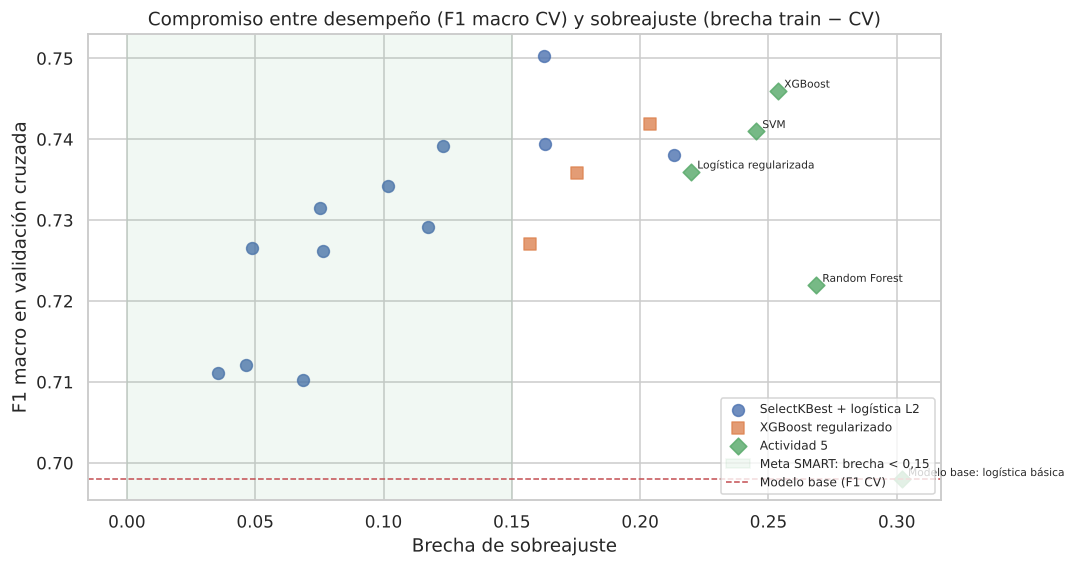

In [4]:
prev = pd.DataFrame({"familia": "Actividad 5", "configuración": act5.index,
                     "F1 CV": act5["F1 macro CV"].astype(str).str[:5].astype(float),
                     "brecha": act5["brecha F1 train-CV"]})
allc = pd.concat([opt, prev], ignore_index=True)
fig, ax = plt.subplots(figsize=(10, 5.5))
for fam, mk in zip(allc["familia"].unique(), ["o", "s", "D"]):
    sub = allc[allc["familia"] == fam]
    ax.scatter(sub["brecha"], sub["F1 CV"], marker=mk, s=60, label=fam, alpha=.8)
for _, r in prev.iterrows():
    ax.annotate(r["configuración"].split(" (")[0], (r["brecha"], r["F1 CV"]), fontsize=7, xytext=(4, 2), textcoords="offset points")
ax.axvspan(0, 0.15, color="#55A868", alpha=.08, label="Meta SMART: brecha < 0,15")
ax.axhline(baseline["classification"]["F1_macro_cv"], color="#C44E52", ls="--", lw=1, label="Modelo base (F1 CV)")
ax.set(title="Compromiso entre desempeño (F1 macro CV) y sobreajuste (brecha train − CV)",
       xlabel="Brecha de sobreajuste", ylabel="F1 macro en validación cruzada")
ax.legend(fontsize=8, loc="lower right")
savefig("28_optimizacion_brecha")
plt.show()

## 3. Selección de los modelos finales (solo con validación cruzada)

In [5]:
ok = opt[opt["brecha"] < 0.15]
if ok.empty:
    print("Ninguna configuración cumple la brecha < 0,15; se elige la de mayor F1 de CV.")
    ok = opt
best_row = ok.sort_values("F1 CV", ascending=False).iloc[0]
src = gs_sel if best_row["familia"].startswith("SelectKBest") else gs_xgb
idx = pd.DataFrame(src.cv_results_)["params"].apply(
    lambda p: ", ".join(f"{k.split('__')[1]}={v}" for k, v in p.items())).tolist().index(best_row["configuración"])
final_clf = src.estimator.set_params(**src.cv_results_["params"][idx]).fit(
    Xc_tr, yc_tr if src is gs_sel else le.transform(yc_tr),
    **({} if src is gs_sel else {"model__sample_weight": compute_sample_weight("balanced", yc_tr)}))
final_clf.set_params(memory=None)
FINAL_CLF_NAME = f"{best_row['familia']} ({best_row['configuración']})"
print("Clasificador final:", FINAL_CLF_NAME)
print(f"  F1 macro CV = {best_row['F1 CV']:.3f} ± {best_row['desv. CV']:.3f} | brecha = {best_row['brecha']:.3f} "
      f"| modelo base CV = {baseline['classification']['F1_macro_cv']:.3f}")
print("Regresor final: Ridge (regla de un error estándar, actividad 5)")
clf_models["Optimizado: " + best_row["familia"]] = final_clf
OPT_NAME = "Optimizado: " + best_row["familia"]

Clasificador final: SelectKBest + logística L2 (C=0.01, k=200)
  F1 macro CV = 0.739 ± 0.017 | brecha = 0.123 | modelo base CV = 0.698
Regresor final: Ridge (regla de un error estándar, actividad 5)


## 4. Evaluación final en el conjunto de prueba: regresión
Para cada modelo se reportan R², RMSE y MAE en prueba, con **intervalos de confianza del 95 % por *bootstrap*** (1.000 remuestreos de las pacientes de prueba). La comparación entre modelos usa el **mismo remuestreo para todos** (*bootstrap* pareado) y la **prueba de Wilcoxon** sobre los errores absolutos de cada paciente.

In [6]:
B = 1000
rng = np.random.default_rng(SEED)
X_te_r, y_te_r = R["test"]
n_te = len(y_te_r)
boot_idx = rng.integers(0, n_te, size=(B, n_te))

# Modelos de referencia (se reajustan solo con entrenamiento, igual que en la actividad 4)
base_lin = Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler()),
                     ("model", LinearRegression())]).fit(R["train"][0][["proliferation_score"]], R["train"][1])
dummy_r = DummyRegressor().fit(R["train"][0], R["train"][1])
preds_r = {"Dummy (media)": dummy_r.predict(X_te_r),
           "Base: lineal simple (proliferación)": base_lin.predict(X_te_r[["proliferation_score"]])}
preds_r.update({k: m.predict(X_te_r) for k, m in reg_models.items()})

def boot_reg(y, p):
    y, p = np.asarray(y), np.asarray(p)
    vals = np.array([[regression_metrics(y[i], p[i])[m] for m in ["R2", "RMSE", "MAE"]] for i in boot_idx])
    return np.percentile(vals, [2.5, 97.5], axis=0)

rows = []
for name, p in preds_r.items():
    m = regression_metrics(y_te_r, p)
    ci = boot_reg(y_te_r, p)
    rows.append({"modelo": name, "R2": m["R2"], "R2 IC95": f"[{ci[0,0]:.3f}, {ci[1,0]:.3f}]",
                 "RMSE": m["RMSE"], "RMSE IC95": f"[{ci[0,1]:.3f}, {ci[1,1]:.3f}]",
                 "MAE": m["MAE"], "MAE IC95": f"[{ci[0,2]:.3f}, {ci[1,2]:.3f}]"})
reg_test = pd.DataFrame(rows).set_index("modelo")
display(reg_test)

,R2,R2 IC95,RMSE,RMSE IC95,MAE,MAE IC95
modelo,,,,,,
Dummy (media),-0.000,"[-0.019, -0.000]",1.048,"[0.964, 1.123]",0.792,"[0.707, 0.872]"
Base: lineal simple (proliferación),0.181,"[0.094, 0.254]",0.949,"[0.871, 1.025]",0.754,"[0.683, 0.825]"
Ridge,0.260,"[0.175, 0.332]",0.902,"[0.838, 0.969]",0.730,"[0.669, 0.796]"
ElasticNet / Lasso,0.248,"[0.163, 0.320]",0.909,"[0.841, 0.981]",0.732,"[0.667, 0.800]"
Random Forest,0.257,"[0.175, 0.327]",0.904,"[0.832, 0.977]",0.729,"[0.665, 0.796]"
XGBoost,0.261,"[0.162, 0.339]",0.901,"[0.832, 0.975]",0.715,"[0.650, 0.787]"


,ΔRMSE (otro − Ridge),IC95 ΔRMSE,p Wilcoxon (errores absolutos)
Ridge frente a,,,
Dummy (media),0.147,"[0.093, 0.198]",0.060
Base: lineal simple (proliferación),0.047,"[0.004, 0.088]",0.354
ElasticNet / Lasso,0.007,"[-0.010, 0.022]",0.739
Random Forest,0.002,"[-0.022, 0.025]",0.841
XGBoost,-0.001,"[-0.024, 0.022]",0.243


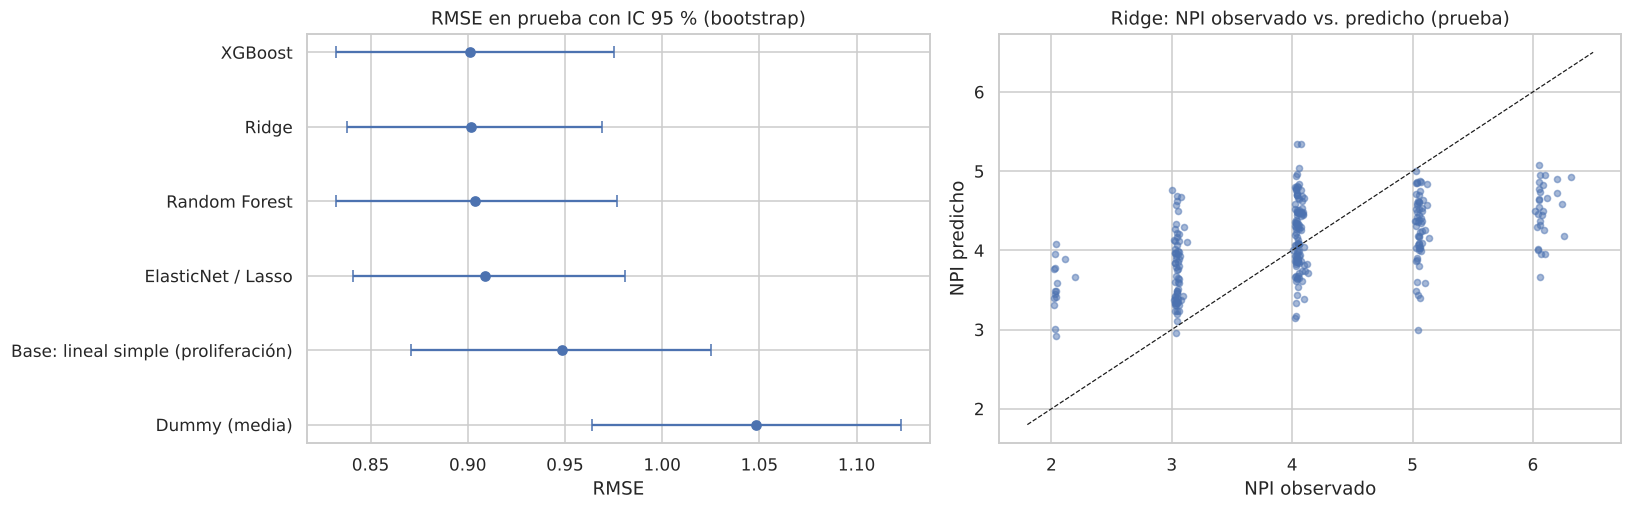

In [7]:
# Comparación pareada de Ridge (modelo final) contra los demás
y_arr = y_te_r.to_numpy()
err = {k: np.abs(y_arr - p) for k, p in preds_r.items()}
rows = []
for name in preds_r:
    if name == "Ridge":
        continue
    d_rmse = np.array([np.sqrt(np.mean((y_arr[i] - preds_r[name][i]) ** 2)) - np.sqrt(np.mean((y_arr[i] - preds_r["Ridge"][i]) ** 2))
                       for i in boot_idx])
    rows.append({"Ridge frente a": name,
                 "ΔRMSE (otro − Ridge)": regression_metrics(y_arr, preds_r[name])["RMSE"] - regression_metrics(y_arr, preds_r["Ridge"])["RMSE"],
                 "IC95 ΔRMSE": f"[{np.percentile(d_rmse, 2.5):.3f}, {np.percentile(d_rmse, 97.5):.3f}]",
                 "p Wilcoxon (errores absolutos)": stats.wilcoxon(err[name], err["Ridge"]).pvalue})
reg_cmp = pd.DataFrame(rows).set_index("Ridge frente a")
display(reg_cmp)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
order = reg_test["RMSE"].sort_values().index
lo = reg_test.loc[order, "RMSE IC95"].str.extract(r"\[(.*), (.*)\]").astype(float)
axes[0].errorbar(reg_test.loc[order, "RMSE"], range(len(order)),
                 xerr=[reg_test.loc[order, "RMSE"] - lo[0], lo[1] - reg_test.loc[order, "RMSE"]], fmt="o", capsize=4)
axes[0].set_yticks(range(len(order)), order)
axes[0].invert_yaxis()
axes[0].set(title="RMSE en prueba con IC 95 % (bootstrap)", xlabel="RMSE")
axes[1].scatter(y_te_r, preds_r["Ridge"], alpha=.5, s=16)
axes[1].plot([1.8, 6.5], [1.8, 6.5], "k--", lw=.8)
axes[1].set(title="Ridge: NPI observado vs. predicho (prueba)", xlabel="NPI observado", ylabel="NPI predicho")
plt.tight_layout()
savefig("29_regresion_prueba")
plt.show()

## 5. Evaluación final en el conjunto de prueba: clasificación
Se evalúan todos los clasificadores: los de referencia, los cuatro de la actividad 5, el optimizado de la sección 2 y el MLP de PyTorch. Las probabilidades del MLP se calculan con `src/mlp.py`; si PyTorch no está instalado en el entorno, se leen de `reports/metrics/act6_mlp_test_proba.csv`, generado con ese mismo módulo. Para comparar pares de modelos sobre las mismas pacientes se usa la **prueba de McNemar** (binomial exacta sobre los casos en que discrepan).

In [8]:
X_te_c, y_te_c = C["test"]
y_te = y_te_c.to_numpy()

def proba_df(model, X):
    p = model.predict_proba(X)
    cols = le.classes_ if isinstance(model[-1], XGBClassifier) else model.classes_
    return pd.DataFrame(p, columns=cols)[CLASSES].to_numpy()

base_log = Pipeline([("pre", build_preprocessor(FS["classification"])),
                     ("model", LogisticRegression(max_iter=3000, class_weight="balanced", random_state=SEED))]).fit(*C["train"])
dummy_c = DummyClassifier(strategy="most_frequent").fit(*C["train"])
dummy_c = Pipeline([("model", dummy_c)])
probas = {"Dummy (clase más frecuente)": proba_df(dummy_c, X_te_c),
          "Base: logística básica": proba_df(base_log, X_te_c)}
for name, m in clf_models.items():
    probas[name] = proba_df(m, X_te_c)
try:
    from src.mlp import predict_split
    mlp_te = predict_split("test")
    print("MLP: probabilidades calculadas con PyTorch en este entorno.")
except Exception as e:
    mlp_te = pd.read_csv(config.METRICS_DIR / "act6_mlp_test_proba.csv")
    print(f"MLP: PyTorch no disponible o versión distinta ({type(e).__name__}); se usan las probabilidades guardadas.")
mlp_te = mlp_te.set_index("patient_id").loc[clf_df.loc[clf_df.split == "test", "patient_id"]]
probas["MLP (PyTorch)"] = mlp_te[CLASSES].to_numpy()
preds_c = {k: np.array(CLASSES)[p.argmax(1)] for k, p in probas.items()}
if "Dummy (clase más frecuente)" in preds_c:
    preds_c["Dummy (clase más frecuente)"] = dummy_c.predict(X_te_c)

boot_c = rng.integers(0, len(y_te), size=(B, len(y_te)))
def boot_clf(y, pred, proba):
    f1s, aucs = [], []
    for i in boot_c:
        f1s.append(f1_score(y[i], pred[i], average="macro", zero_division=0))
        try:
            aucs.append(roc_auc_score(y[i], proba[i], multi_class="ovr", average="macro", labels=CLASSES))
        except ValueError:
            pass
    return np.percentile(f1s, [2.5, 97.5]), np.percentile(aucs, [2.5, 97.5])

rows = []
for name in probas:
    m = classification_metrics(y_te, preds_c[name], probas[name], CLASSES)
    ci_f1, ci_auc = boot_clf(y_te, preds_c[name], probas[name])
    rows.append({"modelo": name, "Accuracy": m["Accuracy"], "Bal. Accuracy": m["Balanced_Accuracy"],
                 "Precision": m["Precision_macro"], "Recall": m["Recall_macro"], "F1 macro": m["F1_macro"],
                 "F1 IC95": f"[{ci_f1[0]:.3f}, {ci_f1[1]:.3f}]", "AUC-ROC": m["AUC_ROC_ovr"],
                 "AUC IC95": f"[{ci_auc[0]:.3f}, {ci_auc[1]:.3f}]"})
clf_test = pd.DataFrame(rows).set_index("modelo").sort_values("F1 macro", ascending=False)
display(clf_test)

MLP: PyTorch no disponible o versión distinta (ModuleNotFoundError); se usan las probabilidades guardadas.


,Accuracy,Bal. Accuracy,Precision,Recall,F1 macro,F1 IC95,AUC-ROC,AUC IC95
modelo,,,,,,,,
Optimizado: SelectKBest + logística L2,0.804,0.797,0.790,0.797,0.792,"[0.735, 0.843]",0.967,"[0.954, 0.977]"
SVM,0.800,0.747,0.790,0.747,0.762,"[0.698, 0.817]",0.968,"[0.958, 0.977]"
Logística regularizada (L2),0.786,0.753,0.764,0.753,0.757,"[0.695, 0.811]",0.969,"[0.957, 0.978]"
XGBoost,0.789,0.745,0.771,0.745,0.753,"[0.691, 0.804]",0.969,"[0.958, 0.979]"
MLP (PyTorch),0.768,0.734,0.731,0.734,0.729,"[0.659, 0.784]",0.962,"[0.949, 0.974]"
Base: logística básica,0.765,0.710,0.735,0.710,0.721,"[0.652, 0.781]",0.958,"[0.944, 0.970]"
Random Forest,0.775,0.695,0.775,0.695,0.719,"[0.645, 0.774]",0.960,"[0.949, 0.970]"
Dummy (clase más frecuente),0.358,0.167,0.060,0.167,0.088,"[0.078, 0.098]",0.500,"[0.500, 0.500]"


In [9]:
def mcnemar(a, b, y):
    ca, cb = a == y, b == y
    n01, n10 = int((ca & ~cb).sum()), int((~ca & cb).sum())
    p = stats.binomtest(min(n01, n10), n01 + n10, 0.5).pvalue if n01 + n10 > 0 else 1.0
    return n01, n10, p

rows = []
for name in preds_c:
    if name == OPT_NAME:
        continue
    n01, n10, p = mcnemar(preds_c[OPT_NAME], preds_c[name], y_te)
    rows.append({"modelo final frente a": name, "aciertos solo del final": n01, "aciertos solo del otro": n10,
                 "p McNemar": p, "diferencia significativa (α = 0,05)": "Sí" if p < 0.05 else "No"})
display(pd.DataFrame(rows).set_index("modelo final frente a"))

,aciertos solo del final,aciertos solo del otro,p McNemar,"diferencia significativa (α = 0,05)"
modelo final frente a,,,,
Dummy (clase más frecuente),149,22,0.000,Sí
Base: logística básica,31,20,0.161,No
Logística regularizada (L2),19,14,0.487,No
SVM,21,20,1.000,No
Random Forest,27,19,0.302,No
XGBoost,18,14,0.597,No
MLP (PyTorch),28,18,0.184,No


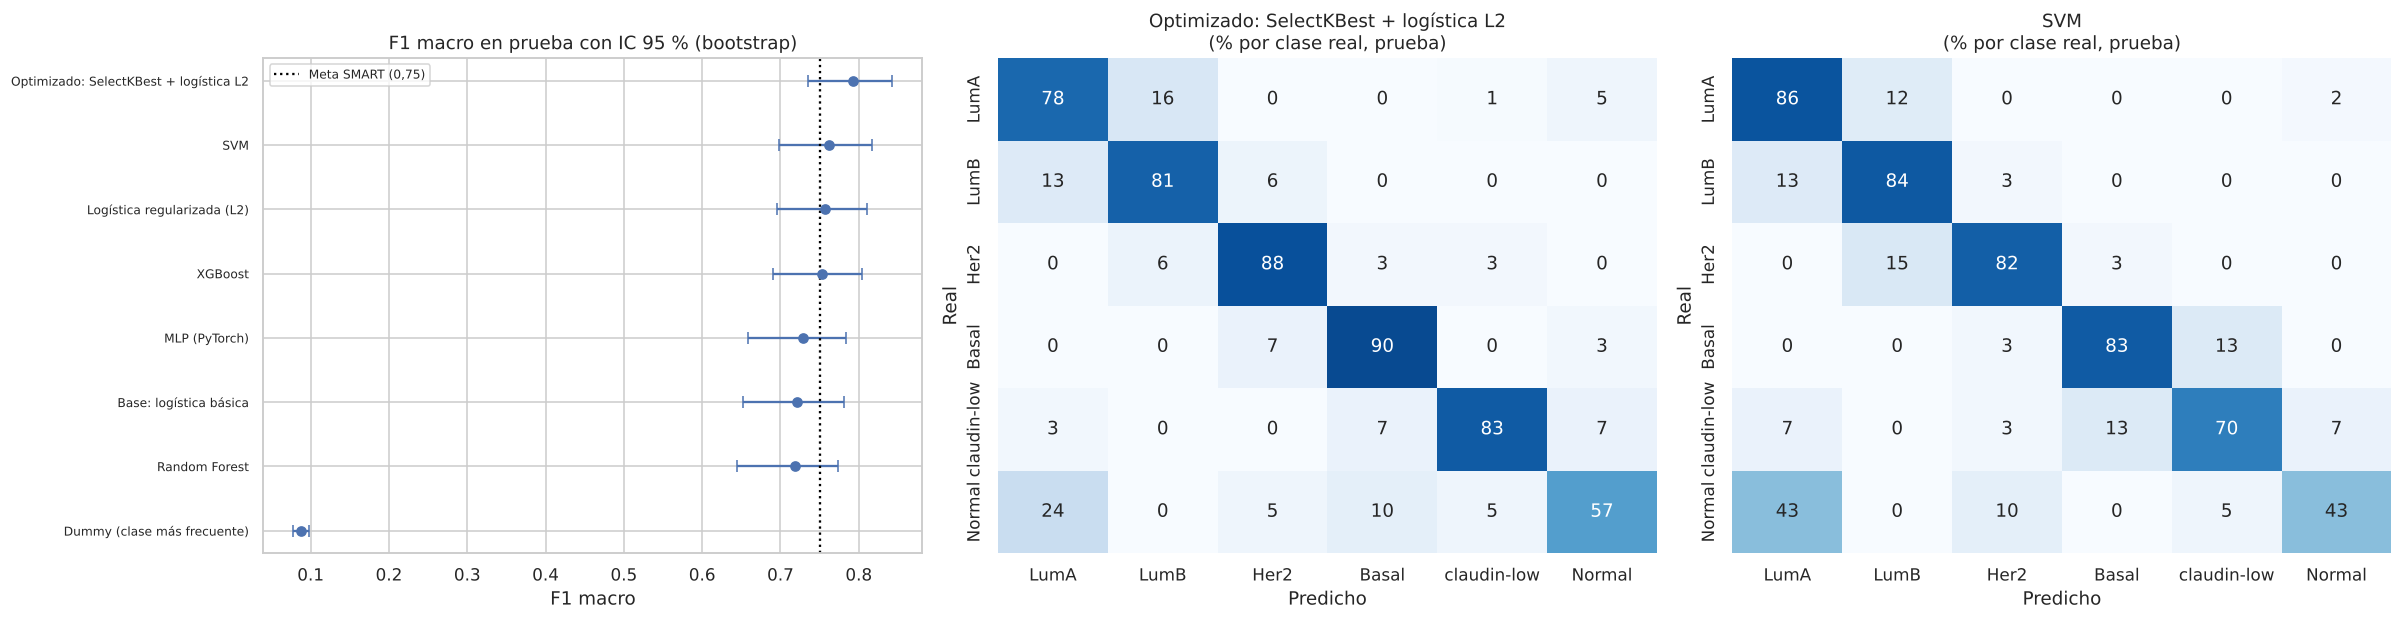

Reporte por clase del clasificador final (prueba):


,precision,recall,f1-score,support
LumA,0.842,0.784,0.812,102.000
LumB,0.757,0.812,0.783,69.000
Her2,0.806,0.879,0.841,33.000
Basal,0.844,0.900,0.871,30.000
claudin-low,0.893,0.833,0.862,30.000
Normal,0.600,0.571,0.585,21.000
accuracy,0.804,0.804,0.804,0.804
macro avg,0.790,0.797,0.792,285.000
weighted avg,0.805,0.804,0.803,285.000


In [10]:
fig, axes = plt.subplots(1, 3, figsize=(22, 5.8))
order = clf_test.index[::-1]
lo = clf_test.loc[order, "F1 IC95"].str.extract(r"\[(.*), (.*)\]").astype(float)
axes[0].errorbar(clf_test.loc[order, "F1 macro"], range(len(order)),
                 xerr=[clf_test.loc[order, "F1 macro"] - lo[0], lo[1] - clf_test.loc[order, "F1 macro"]], fmt="o", capsize=4)
axes[0].axvline(0.75, color="black", ls=":", label="Meta SMART (0,75)")
axes[0].set_yticks(range(len(order)), order, fontsize=8)
axes[0].set(title="F1 macro en prueba con IC 95 % (bootstrap)", xlabel="F1 macro")
axes[0].legend(fontsize=8)
best_unc = clf_test.drop(index=["Dummy (clase más frecuente)"]).index[0]
for ax, name in zip(axes[1:], [OPT_NAME, best_unc if best_unc != OPT_NAME else clf_test.index[1]]):
    cm = confusion_matrix(y_te, preds_c[name], labels=CLASS_ORDER, normalize="true")
    sns.heatmap(cm * 100, annot=True, fmt=".0f", cmap="Blues", xticklabels=CLASS_ORDER, yticklabels=CLASS_ORDER,
                ax=ax, cbar=False, vmin=0, vmax=100)
    ax.set(title=f"{name}\n(% por clase real, prueba)", xlabel="Predicho", ylabel="Real")
plt.tight_layout()
savefig("30_clasificacion_prueba")
plt.show()
print("Reporte por clase del clasificador final (prueba):")
display(pd.DataFrame(classification_report(y_te, preds_c[OPT_NAME], labels=CLASS_ORDER, output_dict=True,
                                           zero_division=0)).T.round(3))

## 6. Interpretabilidad
### 6.1 Regresión (Ridge): coeficientes, SHAP e importancia por permutación
En un modelo lineal con predictores estandarizados, cada coeficiente es el cambio del NPI por desviación estándar del predictor. **SHAP** (*SHapley Additive exPlanations*) reparte la predicción de cada paciente entre los predictores; para un modelo lineal, el valor SHAP es coeficiente × (valor − media). La **importancia por permutación** mide cuánto empeora el RMSE en prueba al desordenar cada variable original.

Background dataset has 1285 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=1285 when initializing the masker.


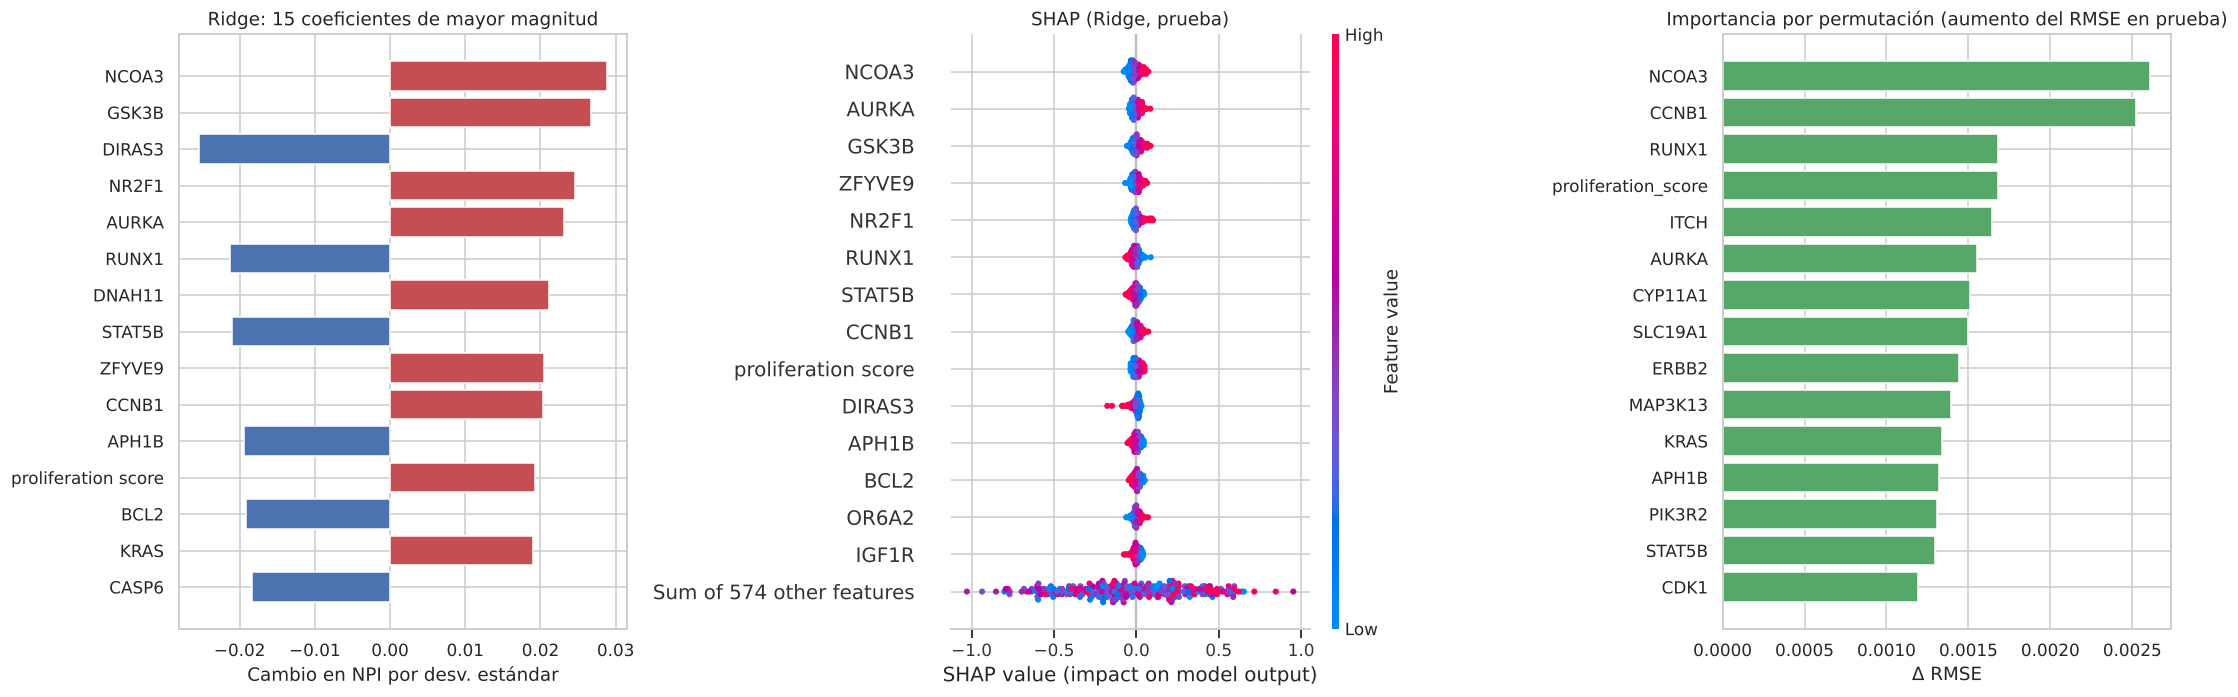

Top 10 por |SHAP| medio: NCOA3, AURKA, GSK3B, ZFYVE9, NR2F1, RUNX1, STAT5B, CCNB1, proliferation score, DIRAS3


In [11]:
def pretty(n):
    block, var = n.split("__", 1)
    if block == "genes":
        return var.upper()
    if block == "binary" and var.endswith("_mut"):
        return var[:-4].upper() + " mutado"
    return var.replace("_", " ")

ridge = reg_models["Ridge"]
pre_r = ridge.named_steps["pre"]
names_r = [pretty(n) for n in pre_r.get_feature_names_out()]
Xt_te_r = pre_r.transform(X_te_r)
Xt_tr_r = pre_r.transform(R["train"][0])
expl_r = shap.LinearExplainer(ridge.named_steps["model"], Xt_tr_r)
sv_r = expl_r(Xt_te_r)
sv_r.feature_names = names_r

perm = permutation_importance(ridge, X_te_r, y_te_r, scoring="neg_root_mean_squared_error", n_repeats=10,
                              random_state=SEED, n_jobs=-1)
perm_s = pd.Series(perm.importances_mean, index=[c.upper() if c in FS["regression"]["genes"] else c for c in reg_cols])

fig = plt.figure(figsize=(20, 6.5))
ax1 = fig.add_subplot(1, 3, 1)
coef = pd.Series(ridge.named_steps["model"].coef_, index=names_r)
top = coef.reindex(coef.abs().sort_values(ascending=False).index[:15])
ax1.barh(top.index[::-1], top.values[::-1], color=["#C44E52" if v > 0 else "#4C72B0" for v in top.values[::-1]])
ax1.set(title="Ridge: 15 coeficientes de mayor magnitud", xlabel="Cambio en NPI por desv. estándar")
ax2 = fig.add_subplot(1, 3, 2)
plt.sca(ax2)
shap.plots.beeswarm(sv_r, max_display=15, show=False, plot_size=None)
ax2.set_title("SHAP (Ridge, prueba)")
ax3 = fig.add_subplot(1, 3, 3)
pt = perm_s.sort_values(ascending=False).head(15)
ax3.barh(pt.index[::-1], pt.values[::-1], color="#55A868")
ax3.set(title="Importancia por permutación (aumento del RMSE en prueba)", xlabel="Δ RMSE")
plt.tight_layout()
savefig("31_interpretabilidad_regresion")
plt.show()
mean_abs_r = pd.Series(np.abs(sv_r.values).mean(0), index=names_r).sort_values(ascending=False)
print("Top 10 por |SHAP| medio:", ", ".join(mean_abs_r.index[:10]))

### 6.2 Clasificación: SHAP de XGBoost y coeficientes del modelo final
XGBoost es el clasificador más flexible; se interpreta con **TreeSHAP**, que calcula los valores de Shapley exactos para árboles. Para el modelo final (selección de variables + logística) se muestran las variables seleccionadas y sus coeficientes por clase, y se mide cuánto coinciden con las de XGBoost.

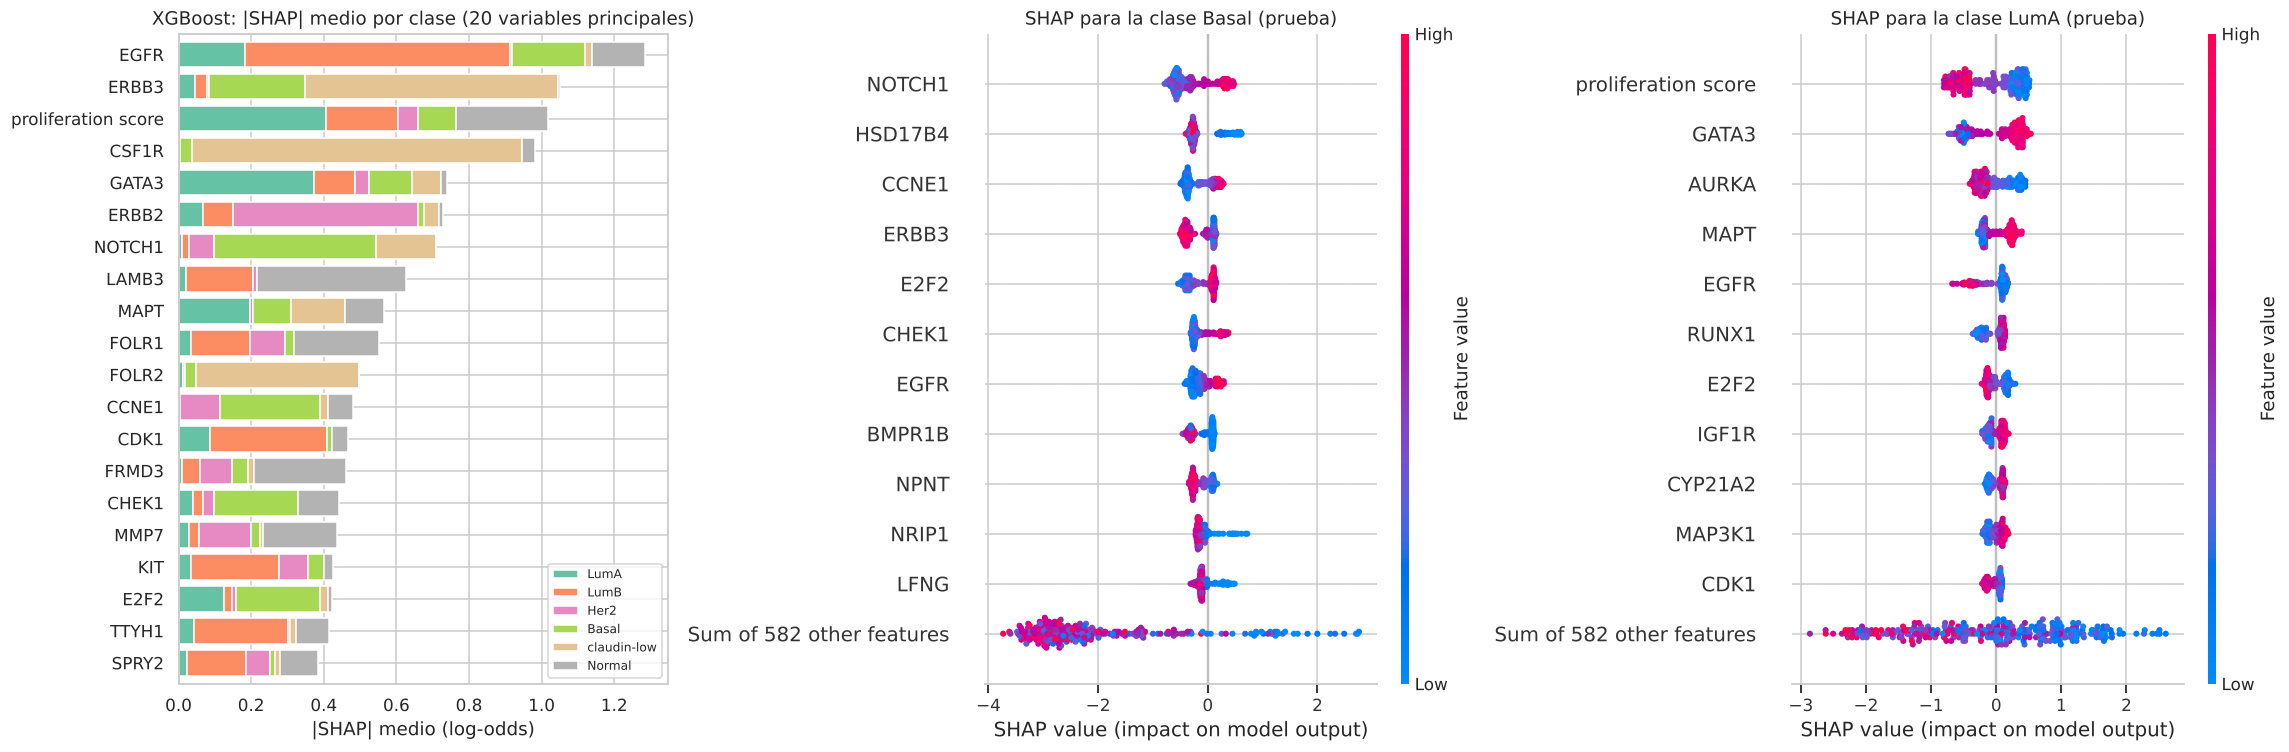

In [12]:
xgb = clf_models["XGBoost"]
pre_x = xgb.named_steps["pre"]
names_x = [pretty(n) for n in pre_x.get_feature_names_out()]
Xt_te_x = pre_x.transform(X_te_c)
expl_x = shap.TreeExplainer(xgb.named_steps["model"])
sv_x = expl_x(Xt_te_x)                     # (pacientes, variables, clases)
sv_x.feature_names = names_x
glob = pd.Series(np.abs(sv_x.values).mean(axis=(0, 2)), index=names_x).sort_values(ascending=False)
per_class = pd.DataFrame(np.abs(sv_x.values).mean(axis=0), index=names_x, columns=CLASSES)

fig = plt.figure(figsize=(21, 7))
ax1 = fig.add_subplot(1, 3, 1)
top = per_class.loc[glob.index[:20], CLASS_ORDER]
top.iloc[::-1].plot(kind="barh", stacked=True, ax=ax1, colormap="Set2", width=.8)
ax1.set(title="XGBoost: |SHAP| medio por clase (20 variables principales)", xlabel="|SHAP| medio (log-odds)")
ax1.legend(fontsize=8)
for k, cls in enumerate(["Basal", "LumA"]):
    ax = fig.add_subplot(1, 3, 2 + k)
    plt.sca(ax)
    shap.plots.beeswarm(sv_x[:, :, CLASSES.index(cls)], max_display=12, show=False, plot_size=None)
    ax.set_title(f"SHAP para la clase {cls} (prueba)")
plt.tight_layout()
savefig("32_shap_clasificacion")
plt.show()

Variables seleccionadas por SelectKBest: 200 de 593
Composición: {'gen': 184, 'clínica/derivada': 15, 'mutación': 1}


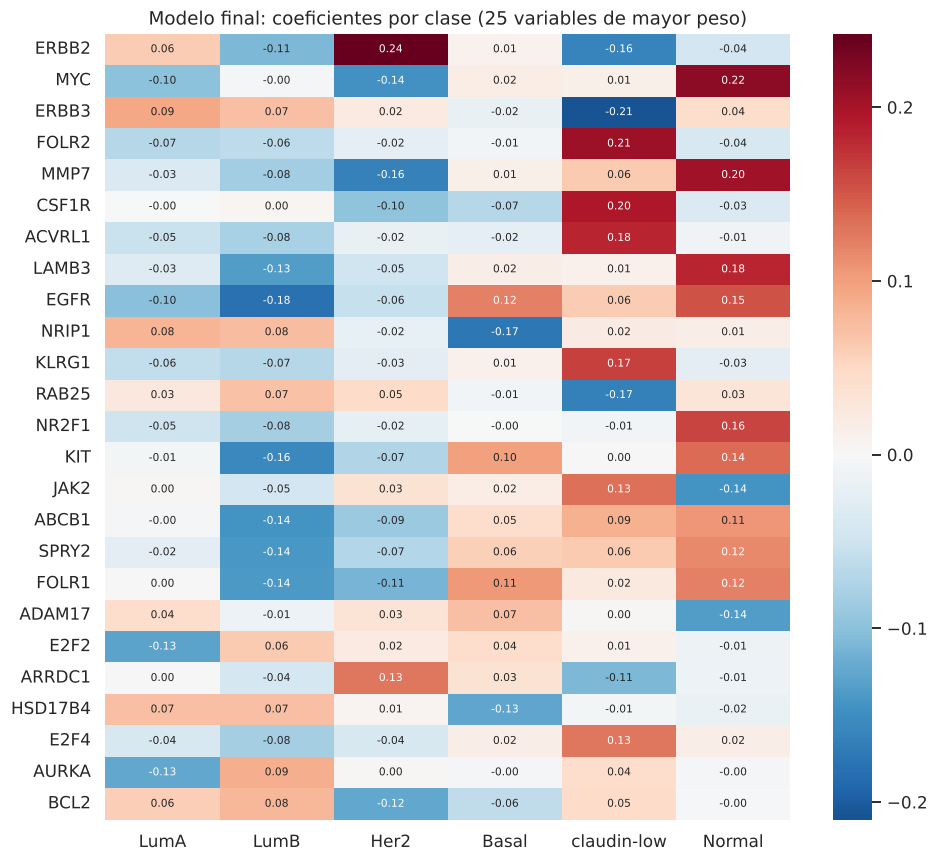

Coincidencia entre las 30 variables principales de XGBoost (SHAP) y del modelo final: 18 de 30


In [13]:
pre_f = final_clf.named_steps["pre"]
names_f = np.array([pretty(n) for n in pre_f.get_feature_names_out()])
if "select" in final_clf.named_steps:
    mask = final_clf.named_steps["select"].get_support()
    sel_names = names_f[mask]
    coefs = pd.DataFrame(final_clf.named_steps["model"].coef_.T, index=sel_names, columns=final_clf.named_steps["model"].classes_)
    print(f"Variables seleccionadas por SelectKBest: {mask.sum()} de {len(mask)}")
    kinds = pd.Series(["gen" if n.isupper() and " " not in n else ("mutación" if "mutado" in n else "clínica/derivada") for n in sel_names]).value_counts()
    print("Composición:", kinds.to_dict())
    top_f = coefs.abs().max(axis=1).sort_values(ascending=False).index[:25]
    fig, ax = plt.subplots(figsize=(9, 8))
    sns.heatmap(coefs.loc[top_f, CLASS_ORDER], cmap="RdBu_r", center=0, annot=True, fmt=".2f", annot_kws={"size": 7}, ax=ax)
    ax.set(title="Modelo final: coeficientes por clase (25 variables de mayor peso)", xlabel="", ylabel="")
    plt.tight_layout()
    savefig("33_coeficientes_modelo_final")
    plt.show()
    overlap = len(set(glob.index[:30]) & set(coefs.abs().max(axis=1).sort_values(ascending=False).index[:30]))
    print(f"Coincidencia entre las 30 variables principales de XGBoost (SHAP) y del modelo final: {overlap} de 30")

## 7. Clustering: validación en prueba y genes que definen los grupos
El K-Means de la actividad 5 se aplica a las pacientes de prueba (proyección y asignación aprendidas en entrenamiento) para verificar que la estructura se mantiene. Luego se identifican los genes que más diferencian a los clústeres, con la prueba de Kruskal-Wallis y la diferencia de medias de cada clúster frente al resto.

,pacientes,silueta,ARI vs PAM50,% clúster 0,% clúster 1,% clúster 2,% clúster 3
subconjunto,,,,,,,
train,1332,0.158,0.209,19.294,32.282,8.183,40.240
val,285,0.155,0.199,14.035,35.439,7.368,43.158
test,286,0.150,0.215,20.629,29.371,6.643,43.357


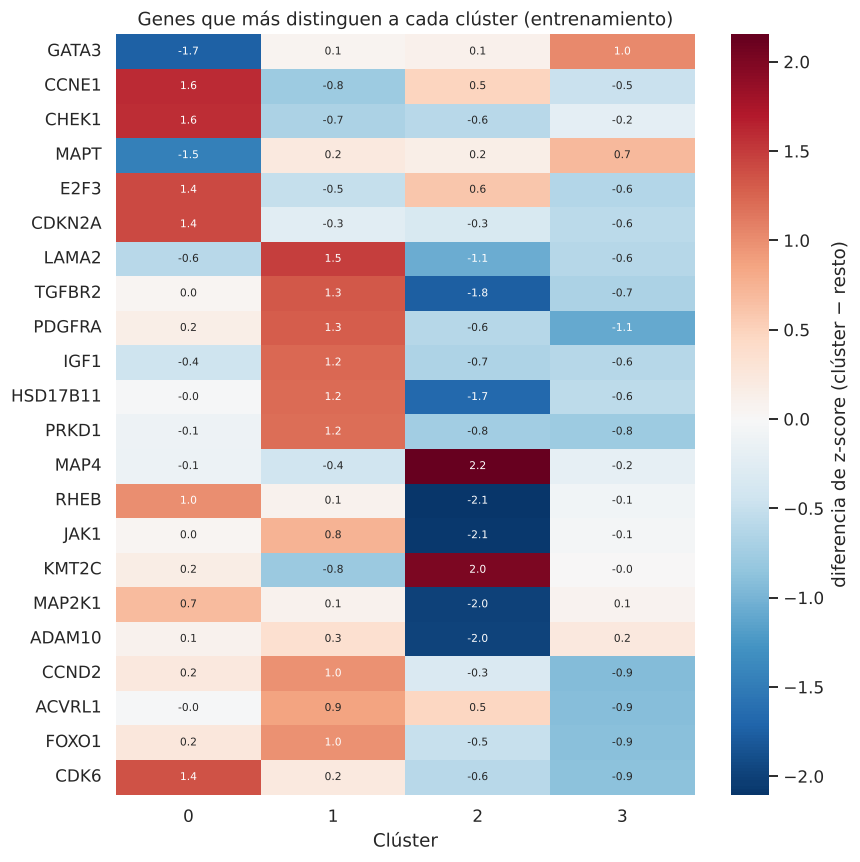

Genes con diferencias significativas entre clústeres (Kruskal-Wallis, Bonferroni): 410 de 489
Clúster 0: más expresados ['CCNE1', 'CHEK1', 'E2F3', 'CDKN2A', 'CDK6'] | menos expresados ['GATA3', 'MAPT', 'APH1B', 'BCL2', 'HSD17B4']
Clúster 1: más expresados ['LAMA2', 'TGFBR2', 'PDGFRA', 'IGF1', 'HSD17B11'] | menos expresados ['E2F2', 'FANCD2', 'AURKA', 'CDC25A', 'SLC19A1']
Clúster 2: más expresados ['MAP4', 'KMT2C', 'AKT1S1', 'ACVR2B', 'SETD1A'] | menos expresados ['RHEB', 'JAK1', 'MAP2K1', 'ADAM10', 'ITGAV']
Clúster 3: más expresados ['GATA3', 'ERBB3', 'IGF1R', 'BMPR1B', 'CCND1'] | menos expresados ['PDGFRA', 'CCND2', 'ACVRL1', 'FOXO1', 'CDK6']


In [14]:
cl = joblib.load(config.MODELS_DIR / "clustering_kmeans.joblib")
genes = cl["genes"]
Z = cl["pca"].transform(cl["scaler"].transform(df[genes]))
lab = cl["kmeans"].predict(Z)
rows = []
for s in ["train", "val", "test"]:
    m = (df.split == s).to_numpy()
    rows.append({"subconjunto": s, "pacientes": int(m.sum()), "silueta": silhouette_score(Z[m], lab[m]),
                 "ARI vs PAM50": adjusted_rand_score(df.loc[m, config.TARGET_CLASSIFICATION], lab[m]),
                 **{f"% clúster {k}": 100 * (lab[m] == k).mean() for k in range(cl["k"])}})
clu_eval = pd.DataFrame(rows).set_index("subconjunto")
display(clu_eval)

tr_mask = (df.split == "train").to_numpy()
kw = {g: stats.kruskal(*[df.loc[tr_mask & (lab == k), g] for k in range(cl["k"])]).pvalue for g in genes}
diff = pd.DataFrame({k: df.loc[tr_mask & (lab == k), genes].mean() - df.loc[tr_mask & (lab != k), genes].mean()
                     for k in range(cl["k"])})
top_genes = []
for k in range(cl["k"]):
    top_genes += diff[k].abs().sort_values(ascending=False).index[:6].tolist()
top_genes = list(dict.fromkeys(top_genes))
fig, ax = plt.subplots(figsize=(8, 8))
sns.heatmap(diff.loc[top_genes].rename(index=str.upper), cmap="RdBu_r", center=0, annot=True, fmt=".1f",
            annot_kws={"size": 7}, ax=ax, cbar_kws={"label": "diferencia de z-score (clúster − resto)"})
ax.set(title="Genes que más distinguen a cada clúster (entrenamiento)", xlabel="Clúster", ylabel="")
plt.tight_layout()
savefig("34_genes_clusteres")
plt.show()
print(f"Genes con diferencias significativas entre clústeres (Kruskal-Wallis, Bonferroni): "
      f"{sum(p < 0.05 / len(genes) for p in kw.values())} de {len(genes)}")
for k in range(cl["k"]):
    up = diff[k].sort_values(ascending=False).index[:5].str.upper().tolist()
    dn = diff[k].sort_values().index[:5].str.upper().tolist()
    print(f"Clúster {k}: más expresados {up} | menos expresados {dn}")

### 7.1 Control de efecto de lote: ¿los clústeres dependen de la cohorte de reclutamiento?
METABRIC reunió muestras de cinco centros (cohortes). Si un clúster se concentra en una sola cohorte, puede reflejar diferencias técnicas de procesamiento (efecto de lote, *batch effect*) y no biología.

In [15]:
from src.eda_utils import cramers_v
ct = pd.crosstab(lab, df["cohort"])
ct.index.name = "clúster"
display((100 * ct.div(ct.sum(axis=1), axis=0)).round(1).rename(columns=lambda c: f"% {c}"))
chi2, p_coh, _, _ = stats.chi2_contingency(ct)
print(f"Chi-cuadrado clúster vs. cohorte: p = {p_coh:.1e}; V de Cramér = {cramers_v(ct):.3f}")
print(f"ARI clúster vs. cohorte: {adjusted_rand_score(df['cohort'], lab):.3f} | ARI clúster vs. PAM50: "
      f"{adjusted_rand_score(df[config.TARGET_CLASSIFICATION], lab):.3f}")
share = (100 * ct.div(ct.sum(axis=1), axis=0)).max(axis=1)
for k in range(cl["k"]):
    print(f"Clúster {k}: {share[k]:.1f} % de sus pacientes provienen de la cohorte {ct.loc[k].idxmax()}")

cohort,% C1,% C2,% C3,% C4,% C5
clúster,,,,,
0,19.100,16.300,39.600,15.400,9.600
1,38.000,22.400,22.400,9.900,7.200
2,0.700,2.700,82.600,2.700,11.400
3,22.600,11.000,42.400,14.800,9.200


Chi-cuadrado clúster vs. cohorte: p = 2.1e-51; V de Cramér = 0.214
ARI clúster vs. cohorte: 0.025 | ARI clúster vs. PAM50: 0.208
Clúster 0: 39.6 % de sus pacientes provienen de la cohorte C3
Clúster 1: 38.0 % de sus pacientes provienen de la cohorte C1
Clúster 2: 82.6 % de sus pacientes provienen de la cohorte C3
Clúster 3: 42.4 % de sus pacientes provienen de la cohorte C3


## 8. Cumplimiento de los objetivos SMART y artefactos finales

In [16]:
opt_cv_f1, opt_gap = best_row["F1 CV"], best_row["brecha"]
smart = pd.DataFrame([
    {"objetivo": "1. Regresión", "criterio": "R² ≥ 0,20 en prueba", "resultado": f"R² = {reg_test.loc['Ridge', 'R2']:.3f}",
     "cumple": reg_test.loc["Ridge", "R2"] >= 0.20},
    {"objetivo": "1. Regresión", "criterio": "RMSE menor que el modelo base (prueba)",
     "resultado": f"{reg_test.loc['Ridge', 'RMSE']:.3f} vs. {reg_test.loc['Base: lineal simple (proliferación)', 'RMSE']:.3f}",
     "cumple": reg_test.loc["Ridge", "RMSE"] < reg_test.loc["Base: lineal simple (proliferación)", "RMSE"]},
    {"objetivo": "2. Clasificación", "criterio": "F1 macro ≥ 0,75 en prueba", "resultado": f"F1 = {clf_test.loc[OPT_NAME, 'F1 macro']:.3f}",
     "cumple": clf_test.loc[OPT_NAME, "F1 macro"] >= 0.75},
    {"objetivo": "2. Clasificación", "criterio": "Superar al modelo base en CV (0,698)", "resultado": f"F1 CV = {opt_cv_f1:.3f}",
     "cumple": opt_cv_f1 > baseline["classification"]["F1_macro_cv"]},
    {"objetivo": "2. Clasificación", "criterio": "Brecha train − CV < 0,15", "resultado": f"brecha = {opt_gap:.3f}",
     "cumple": opt_gap < 0.15},
    {"objetivo": "3. Clustering", "criterio": "K-Means (codo y silueta) + segundo algoritmo + perfiles",
     "resultado": f"K = {cl['k']}; silueta prueba = {clu_eval.loc['test', 'silueta']:.3f}; Ward y DBSCAN evaluados",
     "cumple": True},
]).set_index(["objetivo", "criterio"])
smart["cumple"] = smart["cumple"].map({True: "Sí", False: "No"})
display(smart)

joblib.dump(ridge, config.MODELS_DIR / "final_regressor.joblib", compress=3)
joblib.dump(final_clf, config.MODELS_DIR / "final_classifier.joblib", compress=3)
final_meta = {
    "regressor": {"name": "Ridge", "features": reg_cols, "target": y_reg,
                  "test": {k: float(reg_test.loc["Ridge", k]) for k in ["R2", "RMSE", "MAE"]}},
    "classifier": {"name": FINAL_CLF_NAME, "features": clf_cols, "target": y_clf,
                   "cv_f1_macro": float(opt_cv_f1), "gap": float(opt_gap),
                   "test": {k: float(clf_test.loc[OPT_NAME, k]) for k in ["Accuracy", "F1 macro", "AUC-ROC"]}},
    "clustering": {"file": "clustering_kmeans.joblib", "k": int(cl["k"]),
                   "silhouette_test": float(clu_eval.loc["test", "silueta"])},
}
with open(config.MODELS_DIR / "final_models.json", "w", encoding="utf-8") as f:
    json.dump(final_meta, f, ensure_ascii=False, indent=1)
reg_test.to_csv(config.METRICS_DIR / "act6_regresion_prueba.csv", encoding="utf-8-sig")
reg_cmp.to_csv(config.METRICS_DIR / "act6_regresion_comparacion.csv", encoding="utf-8-sig")
clf_test.to_csv(config.METRICS_DIR / "act6_clasificacion_prueba.csv", encoding="utf-8-sig")
opt.to_csv(config.METRICS_DIR / "act6_optimizacion.csv", index=False, encoding="utf-8-sig")
clu_eval.to_csv(config.METRICS_DIR / "act6_clustering_prueba.csv", encoding="utf-8-sig")
smart.to_csv(config.METRICS_DIR / "act6_smart.csv", encoding="utf-8-sig")
mean_abs_r.head(30).to_csv(config.METRICS_DIR / "act6_shap_regresion_top30.csv", header=["mean_abs_shap"])
glob.head(30).to_csv(config.METRICS_DIR / "act6_shap_clasificacion_top30.csv", header=["mean_abs_shap"])
rmtree(CACHE, ignore_errors=True)
print("Guardado: models/final_regressor.joblib, models/final_classifier.joblib, models/final_models.json y métricas act6_*")

resultado cumple
objetivo         criterio                                                                                                    
1. Regresión     R² ≥ 0,20 en prueba                                                                        R² = 0.260     Sí
                 RMSE menor que el modelo base (prueba)                                                0.902 vs. 0.949     Sí
2. Clasificación F1 macro ≥ 0,75 en prueba                                                                  F1 = 0.792     Sí
                 Superar al modelo base en CV (0,698)                                                    F1 CV = 0.739     Sí
                 Brecha train − CV < 0,15                                                               brecha = 0.123     Sí
3. Clustering    K-Means (codo y silueta) + segundo algoritmo + ...  K = 4; silueta prueba = 0.150; Ward y DBSCAN e...     Sí

Guardado: models/final_regressor.joblib, models/final_classifier.joblib, models/final_models.json y métricas act6_*


## 9. Conclusiones de la actividad 6 (Entregable 3)

**Todos los objetivos SMART se cumplen en el conjunto de prueba** (tabla de la sección 8).

1. **Optimización.** Seleccionar las 200 variables más asociadas al subtipo (ANOVA) antes de una logística L2 con C = 0,01 reduce la brecha de sobreajuste a 0,123 (la meta era menor que 0,15) y mantiene un F1 macro de CV de 0,739, por encima del modelo base (0,698). La configuración con el mayor F1 de CV (0,750; C = 0,03) se descartó por la regla fijada de antemano, porque su brecha es 0,163.
2. **Regresión en prueba.** Ridge obtiene R² = 0,260 (IC 95 %: 0,175 a 0,332), RMSE = 0,902 y MAE = 0,730, por lo que cumple la meta de R² ≥ 0,20. Los cuatro modelos avanzados son estadísticamente equivalentes: los intervalos de la diferencia de RMSE incluyen el 0 y Wilcoxon da p > 0,2. Esto confirma la regla de un error estándar: el modelo más simple no pierde desempeño. Frente al modelo base, Ridge reduce el RMSE en 0,047 (IC: 0,004 a 0,088), aunque Wilcoxon sobre los errores absolutos no es significativo (p = 0,35). La mejora viene sobre todo de reducir los errores grandes, que el RMSE penaliza y la mediana no.
3. **Clasificación en prueba.** El modelo final obtiene el mejor desempeño de todos: F1 macro = 0,792 (IC 95 %: 0,735 a 0,843), exactitud = 0,804 y AUC-ROC = 0,967, con lo que cumple la meta de F1 ≥ 0,75. Las clases mejor reconocidas son Basal (F1 = 0,87), claudin-low (0,86) y HER2 (0,84); Normal-like sigue siendo la más difícil (0,59; el 24 % se confunde con LumA). La prueba de McNemar no encuentra diferencias significativas con los demás modelos ajustados ni con el modelo base (p = 0,16): con 285 pacientes, la prueba no tiene potencia para detectar diferencias de 2 a 7 puntos. Por eso la elección se apoya en la validación cruzada y en el criterio de sobreajuste, y no en la prueba. El MLP (F1 = 0,729) queda por debajo de los modelos lineales y de ensamble.
4. **Interpretabilidad de la regresión.** Los genes que más suben el NPI son de proliferación (AURKA, CCNB1, CDK1, el puntaje de proliferación) y NCOA3 (AIB1), un coactivador del receptor de estrógeno amplificado en cáncer de mama. Los que lo bajan se asocian a diferenciación luminal o a supresión tumoral: BCL2, RUNX1, STAT5B y DIRAS3. Como la regularización es fuerte, el efecto se reparte entre muchos genes con coeficientes pequeños, algo coherente con un rasgo poligénico.
5. **Interpretabilidad de la clasificación.** Los modelos redescubren la biología conocida de los subtipos, lo que les da credibilidad:
   * ERBB2 identifica HER2.
   * GATA3 y ERBB3 marcan los tumores luminales.
   * El puntaje de proliferación separa LumA de LumB.
   * EGFR y NOTCH1 señalan Basal.
   * CSF1R, FOLR2 y KLRG1, genes de macrófagos y células inmunes, caracterizan claudin-low, un subtipo con alto infiltrado inmune y estromal.

   XGBoost (SHAP) y el modelo final (coeficientes) comparten 18 de sus 30 variables principales.
6. **Clustering en prueba.** La estructura se mantiene en las pacientes de prueba: silueta de 0,150 frente a 0,158 en entrenamiento, ARI con PAM50 de 0,215 frente a 0,209 y proporciones similares. Tres clústeres tienen firmas biológicas claras:
   * Clúster 0, proliferativo y basal: CCNE1, CHEK1, E2F3 y CDKN2A altos; GATA3 y BCL2 bajos.
   * Clúster 1, estromal y de baja proliferación: LAMA2, TGFBR2, PDGFRA e IGF1 altos.
   * Clúster 3, luminal: GATA3, ERBB3, IGF1R y CCND1 altos.
7. **Hallazgo crítico: efecto de lote en el clúster 2.** El 82,6 % de sus pacientes proviene de la cohorte C3, frente al 38,5 % en el conjunto completo. Además, sus genes distintivos (MAP4 y KMT2C altos; RHEB, JAK1 y MAP2K1 bajos) no forman una firma biológica coherente. Lo más probable es que ese grupo refleje diferencias técnicas de procesamiento entre centros y no un subtipo tumoral. En conjunto, los clústeres se explican mucho más por la biología que por la cohorte (ARI con PAM50 = 0,208 frente a 0,025 con la cohorte), pero la interpretación del clúster 2 hecha en la actividad 5 debe tomarse con cautela. **Trabajo futuro:** corregir el efecto de lote, por ejemplo con ComBat, antes de segmentar. En el dashboard, el clúster 2 se mostrará con una advertencia.

**Modelos finales para el dashboard (fase 4):** `models/final_regressor.joblib` (Ridge), `models/final_classifier.joblib` (SelectKBest + logística L2) y `models/clustering_kmeans.joblib`, con sus métricas en `models/final_models.json`.